<a href="https://colab.research.google.com/github/Mahtaj-zubaida/Mahtaj-zubaida/blob/main/2nd_project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (accuracy_score,precision_score,recall_score,f1_score,classification_report,confusion_matrix)

In [ ]:
df=pd.read_csv('house_price_classification_1000.csv')

In [ ]:
df.head()

,Area_sqft,Bedrooms,Bathrooms,House_Age,Location,Distance_City_Center,Parking,House_Price_PKR,Price_Category
0,901,3,3,37,Suburban,8.5,No,3060000,Low
1,3983,5,4,24,Suburban,22.5,Yes,30780000,High
2,3446,5,4,7,Urban,13.0,Yes,29170000,High
3,2475,3,3,32,Urban,5.8,Yes,16600000,Medium
4,2449,3,2,5,Suburban,9.3,Yes,10450000,Medium


In [ ]:
df.shape

(1000, 9)

In [ ]:
df.isna().sum()

,0
Area_sqft,0
Bedrooms,0
Bathrooms,0
House_Age,0
Location,0
Distance_City_Center,0
Parking,0
House_Price_PKR,0
Price_Category,0


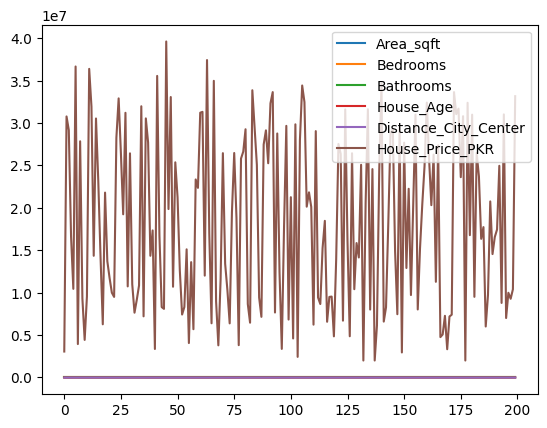

In [ ]:
df.head(200).plot()
plt.show()

In [ ]:
df.columns

Index(['Area_sqft', 'Bedrooms', 'Bathrooms', 'House_Age', 'Location',
       'Distance_City_Center', 'Parking', 'House_Price_PKR', 'Price_Category'],
      dtype='object')

In [ ]:
df['Area_sqft'].value_counts().reset_index().head(5)

,Area_sqft,count
0,1129,4
1,3076,3
2,2452,3
3,4911,3
4,2583,3


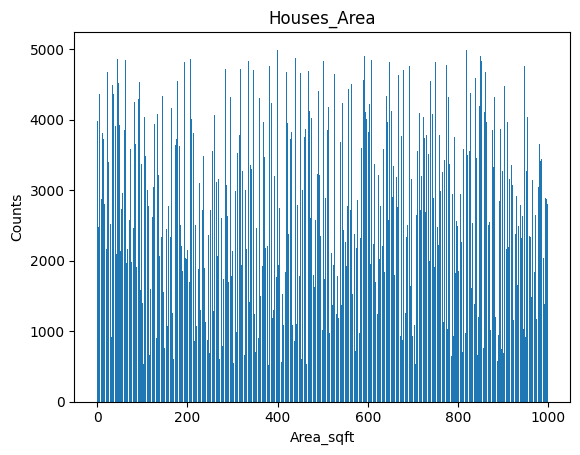

In [ ]:
plt.bar(df['Area_sqft'].index,df['Area_sqft'].values)
plt.title('Houses_Area')
plt.xlabel('Area_sqft')
plt.ylabel('Counts')
plt.show()


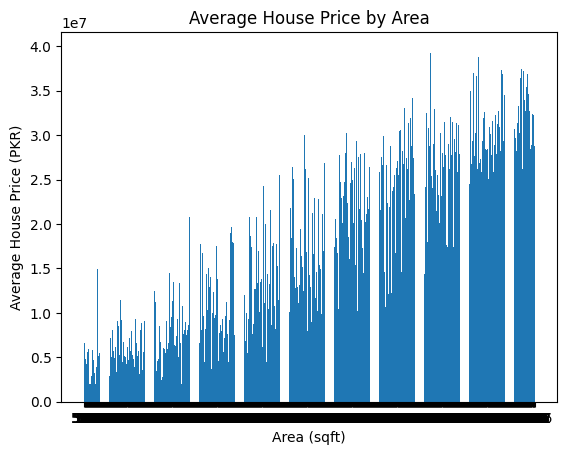

In [ ]:
Avg_price = df.groupby('Area_sqft')['House_Price_PKR'].mean()

plt.bar(Avg_price.index.astype(str), Avg_price.values)
plt.title('Average House Price by Area')
plt.xlabel('Area (sqft)')
plt.ylabel('Average House Price (PKR)')
plt.show()

In [ ]:
price_cat_summary=df.groupby('Price_Category')['House_Price_PKR'].mean()
price_cat_summary
price_cat_summary= price_cat_summary.reindex(['High', 'Medium','Low'])


Text(0, 0.5, 'Average House Price (PKR)')

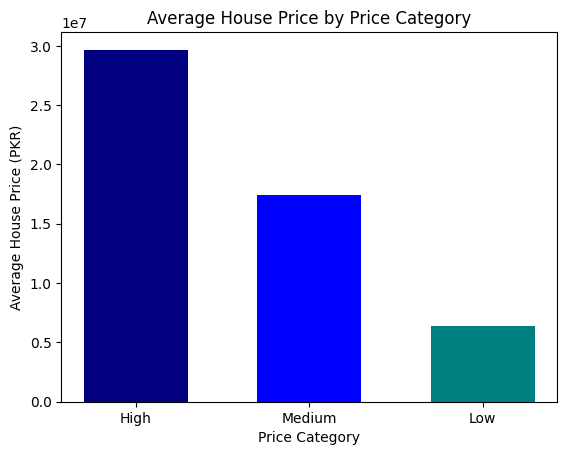

In [ ]:
color_map = {'Low': 'teal', 'Medium': 'blue', 'High': 'navy'}
colors = [color_map.get(cat, 'gray') for cat in price_cat_summary.index]

plt.bar(price_cat_summary.index,price_cat_summary.values,color=colors,width=0.6)
plt.title('Average House Price by Price Category')
plt.xlabel('Price Category')
plt.ylabel('Average House Price (PKR)')

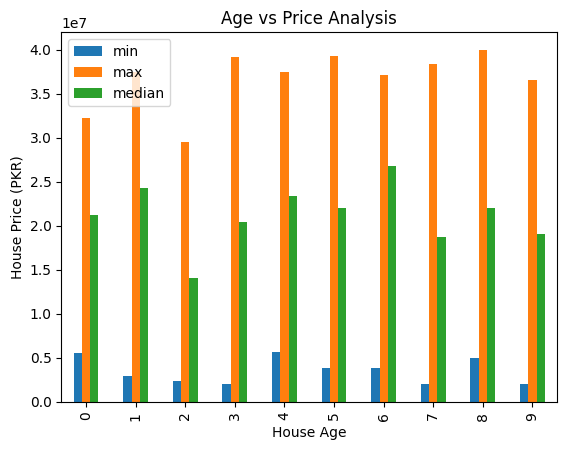

In [ ]:
Age_vs_price = df.groupby('House_Age')['House_Price_PKR'].agg(['min', 'max', 'median'])
Age_vs_price.head(10).plot(kind='bar')
plt.title('Age vs Price Analysis')
plt.xlabel('House Age')
plt.ylabel('House Price (PKR)')
plt.show()

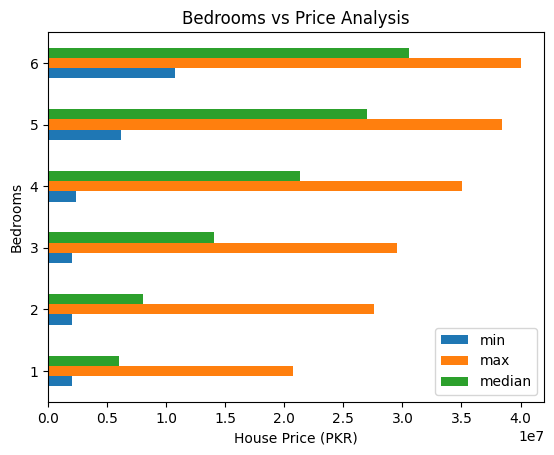

In [ ]:
Bedroom_vs_price = df.groupby('Bedrooms')['House_Price_PKR'].agg(['min', 'max', 'median'])
Bedroom_vs_price.head(10).plot(kind='barh')
plt.title('Bedrooms vs Price Analysis')
plt.ylabel('Bedrooms')
plt.xlabel('House Price (PKR)')
plt.show()

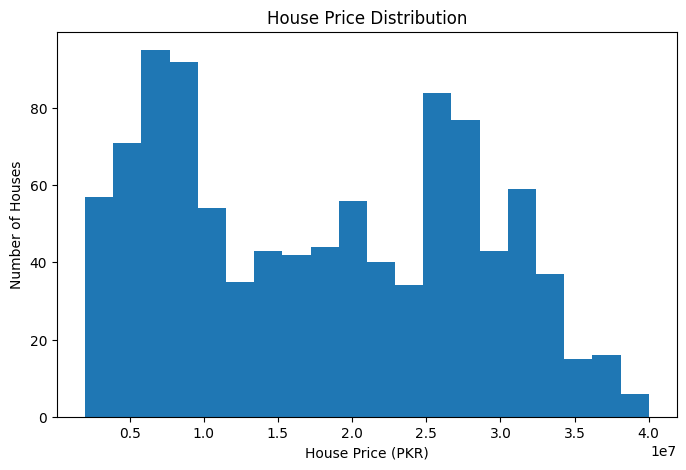

In [ ]:
plt.figure(figsize=(8, 5))

plt.hist(df['House_Price_PKR'], bins=20)

plt.title('House Price Distribution')
plt.xlabel('House Price (PKR)')
plt.ylabel('Number of Houses')

plt.show()

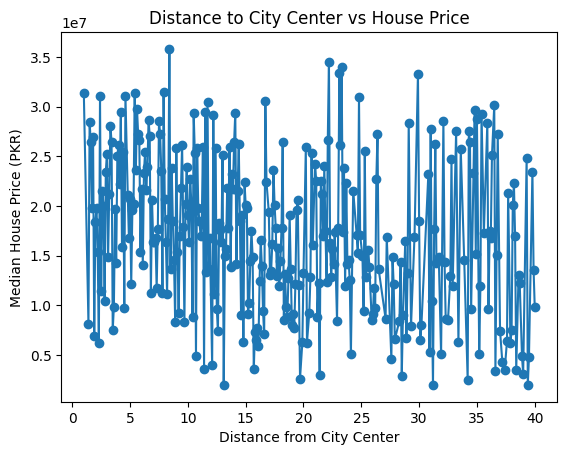

In [ ]:
distance_vs_price = df.groupby('Distance_City_Center')['House_Price_PKR'].median()

distance_vs_price.plot(kind='line', marker='o')

plt.title('Distance to City Center vs House Price')
plt.xlabel('Distance from City Center')
plt.ylabel('Median House Price (PKR)')
plt.show()

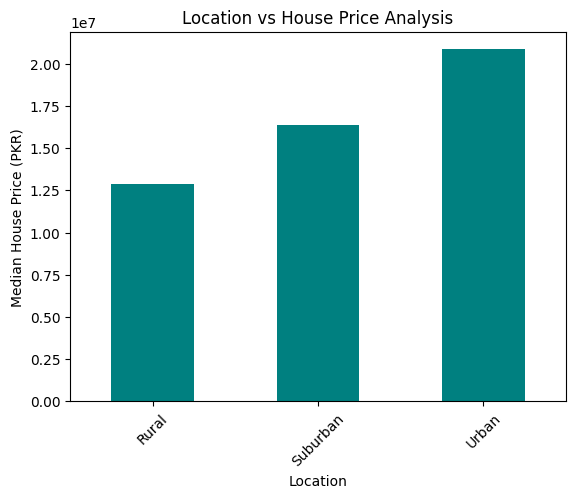

In [ ]:
location_price = df.groupby('Location')['House_Price_PKR'].median()

location_price.plot(kind='bar', color='teal')

plt.title('Location vs House Price Analysis')
plt.xlabel('Location')
plt.ylabel('Median House Price (PKR)')
plt.xticks(rotation=45)
plt.show()

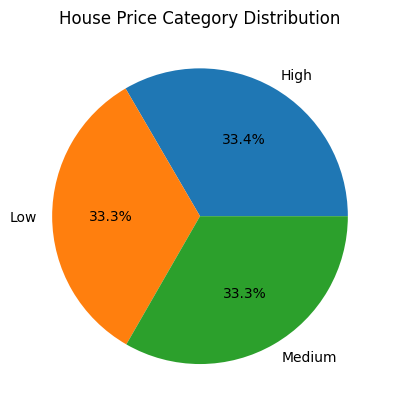

In [ ]:
df['Price_Category'].value_counts().plot(kind='pie', autopct='%1.1f%%')

plt.title('House Price Category Distribution')
plt.ylabel('')
plt.show()

In [ ]:
from sklearn.model_selection import train_test_split

x = df.drop(columns=['House_Price_PKR', 'Price_Category'])
y = df['Price_Category']

x = pd.get_dummies(x, columns=['Location', 'Parking'], dtype=int)

x_train, x_test, y_train, y_test = train_test_split(
    x, y, test_size=0.2, random_state=42
)

print(x_train.shape)
print(x_test.shape)

(800, 10)
(200, 10)


In [ ]:
display(x_train.head())

,Area_sqft,Bedrooms,Bathrooms,House_Age,Distance_City_Center,Location_Rural,Location_Suburban,Location_Urban,Parking_No,Parking_Yes
29,2495,2,2,12,7.0,0,0,1,0,1
535,1191,2,2,2,37.4,1,0,0,0,1
695,1640,2,2,22,30.9,1,0,0,0,1
557,4438,6,4,1,38.7,1,0,0,0,1
836,4138,5,4,19,7.2,0,0,1,0,1


In [ ]:
print(x_train.dtypes)
print(x_train.head())
print(x_train.shape)
print(x_test.shape)

Area_sqft                 int64
Bedrooms                  int64
Bathrooms                 int64
House_Age                 int64
Distance_City_Center    float64
Location_Rural            int64
Location_Suburban         int64
Location_Urban            int64
Parking_No                int64
Parking_Yes               int64
dtype: object
     Area_sqft  Bedrooms  Bathrooms  House_Age  Distance_City_Center  \
29        2495         2          2         12                   7.0   
535       1191         2          2          2                  37.4   
695       1640         2          2         22                  30.9   
557       4438         6          4          1                  38.7   
836       4138         5          4         19                   7.2   

     Location_Rural  Location_Suburban  Location_Urban  Parking_No  \
29                0                  0               1           0   
535               1                  0               0           0   
695               1    

In [ ]:
model_1 = DecisionTreeClassifier(
    criterion='gini',
    max_depth=3,
    min_samples_leaf=3,
    random_state=42)

model_1.fit(x_train, y_train)
print('Model trained sucessfully')

Model trained sucessfully


In [ ]:
y_pred = model_1.predict(x_test)

print(y_pred)

['Low' 'Low' 'High' 'Low' 'Low' 'Medium' 'Low' 'High' 'High' 'Medium'
 'High' 'Medium' 'Low' 'Medium' 'Medium' 'Medium' 'Medium' 'Low' 'Medium'
 'High' 'Medium' 'Medium' 'Medium' 'Low' 'Medium' 'High' 'Low' 'Medium'
 'Low' 'Low' 'High' 'Medium' 'Medium' 'Medium' 'Low' 'Medium' 'Medium'
 'Medium' 'Low' 'Medium' 'Low' 'Low' 'Low' 'Low' 'Low' 'High' 'Low' 'High'
 'Medium' 'Low' 'High' 'Medium' 'Low' 'High' 'High' 'Medium' 'Medium'
 'Medium' 'Medium' 'Low' 'High' 'Medium' 'Medium' 'High' 'High' 'High'
 'Low' 'High' 'High' 'Low' 'Medium' 'Medium' 'High' 'High' 'High' 'Medium'
 'Low' 'Medium' 'High' 'Medium' 'High' 'High' 'Medium' 'Low' 'High'
 'Medium' 'High' 'High' 'High' 'Low' 'High' 'High' 'Low' 'Medium' 'Medium'
 'Medium' 'Medium' 'High' 'High' 'Medium' 'Medium' 'Low' 'Low' 'Medium'
 'Medium' 'High' 'High' 'Medium' 'Low' 'High' 'High' 'Medium' 'Medium'
 'Low' 'Low' 'High' 'Medium' 'Low' 'Medium' 'Medium' 'Medium' 'Low' 'High'
 'High' 'Medium' 'High' 'Low' 'Medium' 'High' 'Low' 'Medium' 

In [ ]:
from sklearn.metrics import accuracy_score

accuracy = accuracy_score(y_test, y_pred)

print("Accuracy:", accuracy)
print("Accuracy Percentage:", accuracy * 100, "%")

Accuracy: 0.79
Accuracy Percentage: 79.0 %


In [ ]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_pred)

print(cm)

[[53  0 17]
 [ 0 52 11]
 [11  3 53]]


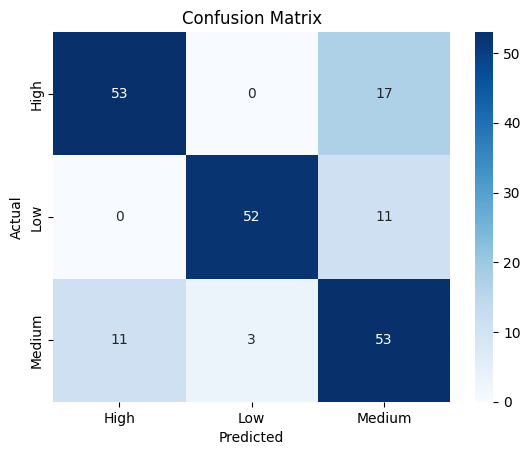

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=model_1.classes_,
            yticklabels=model_1.classes_)

plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix')
plt.show()

In [ ]:
from sklearn.metrics import classification_report

print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

        High       0.83      0.76      0.79        70
         Low       0.95      0.83      0.88        63
      Medium       0.65      0.79      0.72        67

    accuracy                           0.79       200
   macro avg       0.81      0.79      0.80       200
weighted avg       0.81      0.79      0.79       200



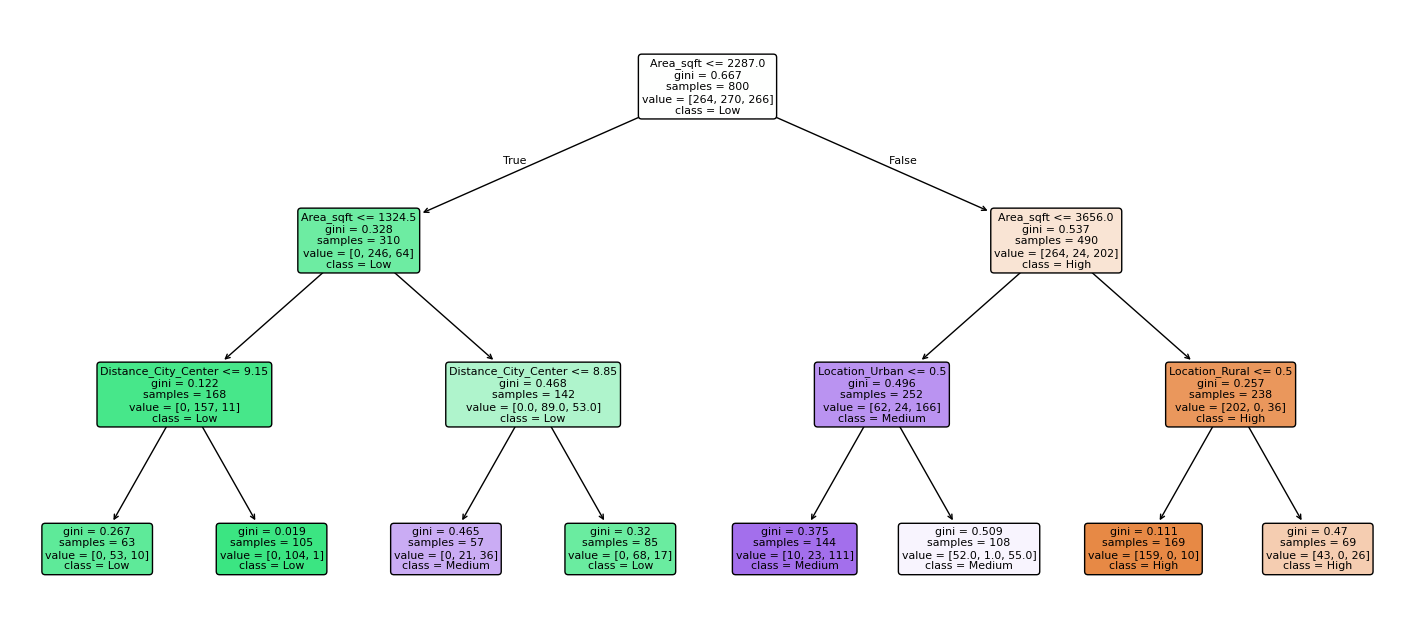

In [ ]:
from sklearn.tree import plot_tree

plt.figure(figsize=(18, 8))

plot_tree(
    model_1,
    feature_names=x_train.columns,
    class_names=model_1.classes_,
    filled=True,
    rounded=True
)

plt.show()